<a href="https://colab.research.google.com/github/teddiclax/Carbon__Deposition__Prediction-Catalytic-Methane-Pyrolysis-/blob/teddiclax/HVO__DIESEL__BLENDING__COMPUTATIONAL__CODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
### Import necessary libraries ###
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
import seaborn as sns
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
from __future__ import annotations
import os
import re
import json
import random
from typing import Dict, List, Tuple, Optional
import torch
import torch.nn as nn
import torch.optim as optim
from pandas.api.types import is_numeric_dtype
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

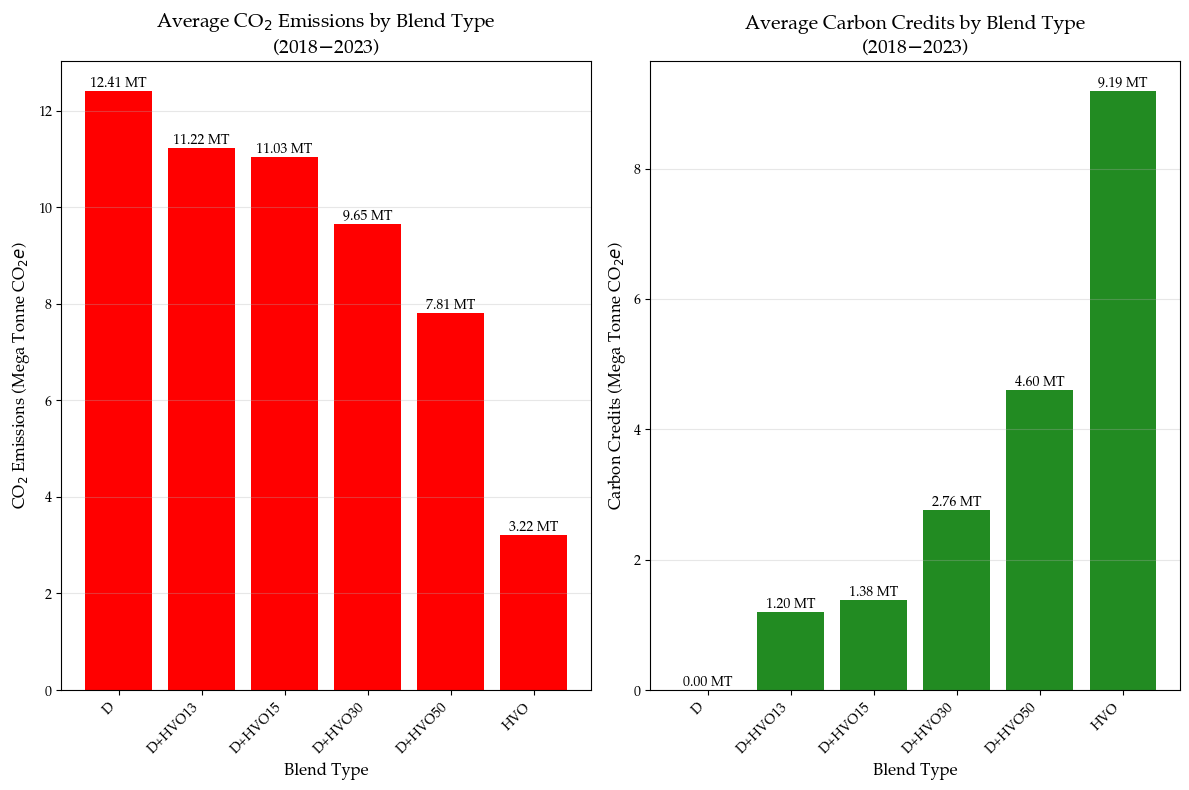

In [ ]:
### HISTOGRAM PLOT FOR EMISSIONS AND CARBON CREDIT ###

## For Latex rendering and Font Selection ##
font_path = "/content/Palatia.ttf"
fm.fontManager.addfont(font_path)
komika = fm.FontProperties(fname=font_path)
plt.rcParams['font.family'] = komika.get_name()
plt.rcParams['text.usetex'] = False

## Importing Diesel Consumption and the corresponding CO2 Emissions data ##
df = pd.read_csv('/content/DIESEL__DATA.csv')

## Convert 'tCO2e per year' to numeric ##
df['tCO2e per year'] = df['tCO2e per year'].astype(str).str.replace(',', '').astype(float)

## Defining Emission factors (kg CO₂e per liter) ##
EF_DIESEL = 2.7
EF_HVO = 0.7

## Defining Blending Combinations ##
blends = {
    'D+HVO13': 13,
    'D+HVO15': 15,
    'D+HVO30': 30,
    'D+HVO50': 50,
    'D': 0,
    'HVO': 100
}

## Compute Blending Emission Factors ##
def calculate_blend_ef(hvo_percentage):
    diesel_pct = 100 - hvo_percentage
    return (diesel_pct/100 * EF_DIESEL) + (hvo_percentage/100 * EF_HVO)

## Compute Emissions and Credits ##
results = []
for _, row in df.iterrows():
    year = row['Year']
    baseline_emissions = row['tCO2e per year']
    total_fuel = (baseline_emissions * 1000) / EF_DIESEL

    for blend_name, hvo_pct in blends.items():
        blend_ef = calculate_blend_ef(hvo_pct)
        blend_emissions = (total_fuel * blend_ef) / 1000
        carbon_credits = baseline_emissions - blend_emissions

        results.append({
            'Year': year,
            'Blend': blend_name,
            'HVO_Percentage': hvo_pct,
            'CO2e_Emissions_MT': blend_emissions / 1000000,
            'Carbon_Credits_MT': max(0, carbon_credits) / 1000000
        })

results_df = pd.DataFrame(results)

## Histogram Plot A: CO2 Emissions (Measured in Mega Tonne CO₂e) Versus Blend Type ##
plt.figure(figsize=(12, 8))

## Compute Average Emissions for each Blend ##
avg_emissions = results_df.groupby('Blend')['CO2e_Emissions_MT'].mean().sort_values()

## Create an ordered list based on HVO percentage ##
blend_order = ['D', 'D+HVO13', 'D+HVO15', 'D+HVO30', 'D+HVO50', 'HVO']
avg_emissions_ordered = [avg_emissions[blend] for blend in blend_order]

plt.subplot(1, 2, 1)
bars = plt.bar(blend_order, avg_emissions_ordered,
               color=['#FF0000'])
plt.ylabel('CO${_2}$ Emissions (Mega Tonne CO${_2}e$)', fontsize=12, fontweight='bold', usetex=False)
plt.xlabel('Blend Type', fontsize=12, fontweight='bold', usetex=False)
plt.title('Average CO${_2}$ Emissions by Blend Type\n(2018$-$2023)', fontsize=14, fontweight='bold', usetex=False)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

## Inserting value labels on each bar ##
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f} MT', ha='center', va='bottom', fontweight='bold', usetex=False)

## Histogram Plot B: Carbon Credits (Measured in Mega Tonne CO₂e) Versus Blend Type ##
plt.subplot(1, 2, 2)
avg_credits = results_df.groupby('Blend')['Carbon_Credits_MT'].mean()
avg_credits_ordered = [avg_credits[blend] for blend in blend_order]

bars = plt.bar(blend_order, avg_credits_ordered,
               color=['#228B22'])
plt.ylabel('Carbon Credits (Mega Tonne CO${_2}e$)', fontsize=12, fontweight='bold', usetex=False)
plt.xlabel('Blend Type', fontsize=12, fontweight='bold', usetex=False)
plt.title('Average Carbon Credits by Blend Type\n(2018$-$2023)', fontsize=14, fontweight='bold', usetex=False)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

## Inserting value labels on each bar ##
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.2f} MT', ha='center', va='bottom', fontweight='bold', usetex=False)

plt.tight_layout()
plt.savefig("Histogram_Plot_HVO.png", dpi=600)
plt.show()

QUADRATIC REGRESSION MODEL FOR CO₂ EMISSIONS PREDICTION

D+HVO13    - R²: 0.650, MAE: 0.822, MSE: 0.983
          2030 Prediction: 50.99 MT
          2040 Prediction: 190.23 MT
          2050 Prediction: 427.80 MT

D+HVO15    - R²: 0.650, MAE: 0.809, MSE: 0.951
          2030 Prediction: 50.15 MT
          2040 Prediction: 187.11 MT
          2050 Prediction: 420.79 MT

D+HVO30    - R²: 0.650, MAE: 0.708, MSE: 0.728
          2030 Prediction: 43.88 MT
          2040 Prediction: 163.72 MT
          2050 Prediction: 368.19 MT

D+HVO50    - R²: 0.650, MAE: 0.573, MSE: 0.477
          2030 Prediction: 35.52 MT
          2040 Prediction: 132.54 MT
          2050 Prediction: 298.06 MT

D          - R²: 0.650, MAE: 0.910, MSE: 1.204
          2030 Prediction: 56.42 MT
          2040 Prediction: 210.50 MT
          2050 Prediction: 473.39 MT

HVO        - R²: 0.650, MAE: 0.236, MSE: 0.081
          2030 Prediction: 14.63 MT
          2040 Prediction: 54.57 MT
          2050 Prediction: 122.73 

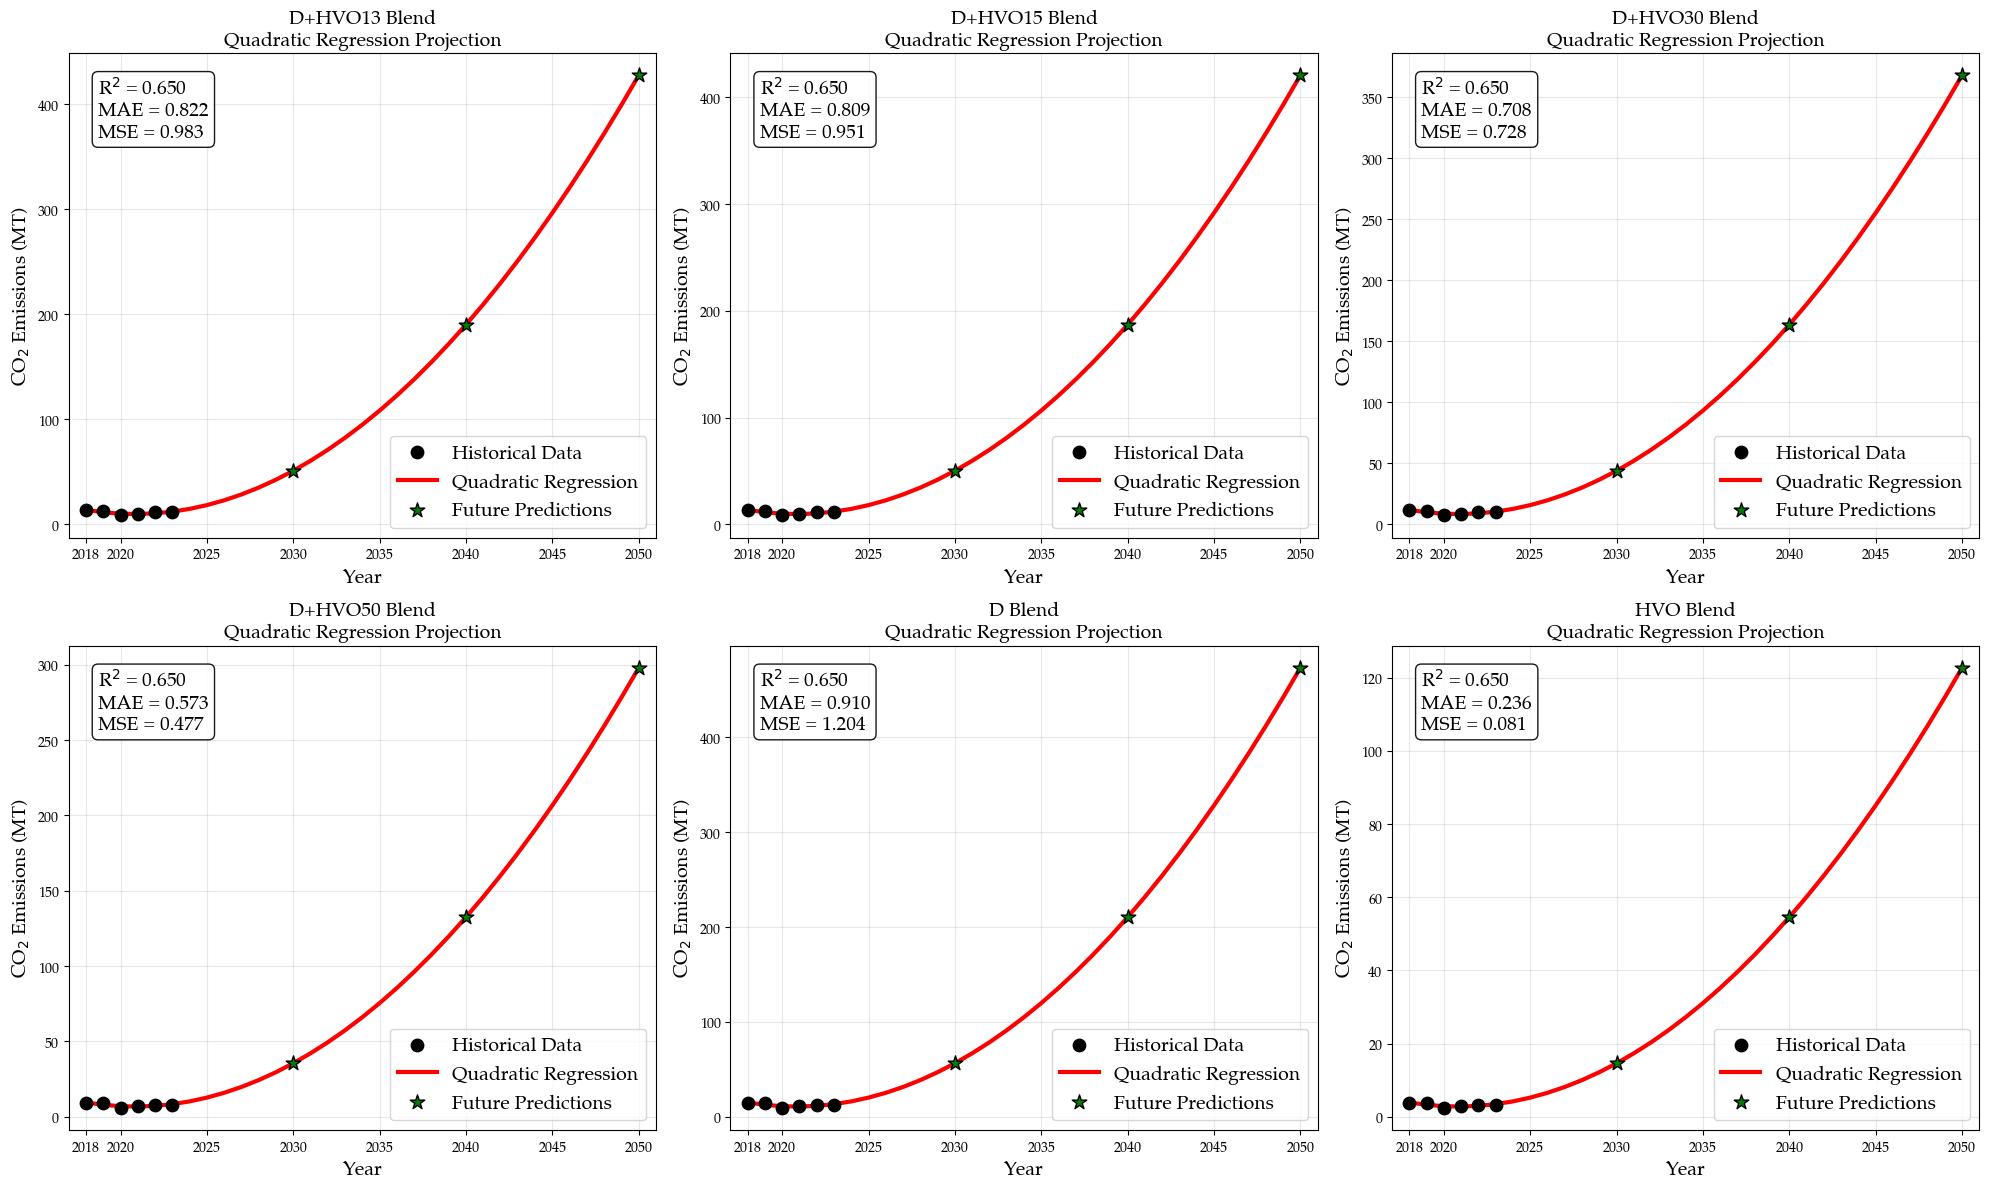


SUMMARY OF CO₂ EMISSIONS PREDICTIONS USING QUADRATIC REGRESSION (Mega Tonnes)
     Blend  HVO_%    R²    MAE    MSE  2030_Pred_MT  2040_Pred_MT  \
0  D+HVO13     13  0.65  0.822  0.983        50.986       190.229   
1  D+HVO15     15  0.65  0.809  0.951        50.150       187.111   
2  D+HVO30     30  0.65  0.708  0.728        43.881       163.722   
3  D+HVO50     50  0.65  0.573  0.477        35.523       132.537   
4        D      0  0.65  0.910  1.204        56.419       210.500   
5      HVO    100  0.65  0.236  0.081        14.627        54.574   

   2050_Pred_MT  
0       427.802  
1       420.789  
2       368.190  
3       298.059  
4       473.387  
5       122.730  

CARBON CREDIT POTENTIAL IN FUTURE YEARS USING QUADRATIC REGRESSION (Mega Tonnes)
Projected Baseline Emissions (100% Diesel - Quadratic Model):
2030: 56.42 MT
2040: 210.50 MT
2050: 473.39 MT

D+HVO13   : 2030 Credits: 5.43 MT (9.63%)
          2040 Credits: 20.27 MT (9.63%)
          2050 Credits: 45.59 MT (9.

In [ ]:
### GRAPHICAL PLOT FOR THE DEPLOYED QUADRATIC REGRESSION MODEL ###
print("QUADRATIC REGRESSION MODEL FOR CO₂ EMISSIONS PREDICTION")
print("=" * 70)

## Initialize results storage ##
regression_results = {}
future_predictions = {}

## Define Target years for prediction ##
future_years = [2030, 2040, 2050]

for blend in blends.keys():
    blend_data = results_df[results_df['Blend'] == blend].copy()

    ## Prepare features (Year) and target (CO2 Emissions) ##
    X = blend_data[['Year']].values
    y = blend_data['CO2e_Emissions_MT'].values

    ## Create and fit Quadratic regression model ##
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    ##  Make predictions for historical years  ##
    y_pred = model.predict(X_poly)

    ## Compute Metrics ##
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)
    mse = mean_squared_error(y, y_pred)

    ## Predict for future years ##
    future_X = np.array(future_years).reshape(-1, 1)
    future_X_poly = poly.transform(future_X)
    future_y_pred = model.predict(future_X_poly)

    ## Store results ##
    regression_results[blend] = {
        'model': model,
        'poly': poly,
        'r2': r2,
        'mae': mae,
        'mse': mse,
        'future_predictions': dict(zip(future_years, future_y_pred))
    }

    future_predictions[blend] = future_y_pred

    print(f"\n{blend:10} - R²: {r2:.3f}, MAE: {mae:.3f}, MSE: {mse:.3f}")
    print(f"          2030 Prediction: {future_y_pred[0]:.2f} MT")
    print(f"          2040 Prediction: {future_y_pred[1]:.2f} MT")
    print(f"          2050 Prediction: {future_y_pred[2]:.2f} MT")

## Plot Quadratic regression graph for each blend type  ##
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

## Extended year range for plotting ##
plot_years = np.arange(2018, 2051).reshape(-1, 1)

for idx, blend in enumerate(blends.keys()):
    blend_data = results_df[results_df['Blend'] == blend]
    model_info = regression_results[blend]

    ## Historical data ##
    axes[idx].scatter(blend_data['Year'], blend_data['CO2e_Emissions_MT'],
                     color='black', s=80, label='Historical Data', zorder=5)

    ## Quadratic Regression Curve ##
    plot_years_poly = model_info['poly'].transform(plot_years)
    all_years_pred = model_info['model'].predict(plot_years_poly)
    axes[idx].plot(plot_years, all_years_pred, 'r-', linewidth=3,
                  label='Quadratic Regression', zorder=4)

    ## Future predictions the year 2030, 2040 and, 2050 ##
    future_2030 = model_info['future_predictions'][2030]
    future_2040 = model_info['future_predictions'][2040]
    future_2050 = model_info['future_predictions'][2050]

    axes[idx].scatter([2030, 2040, 2050], [future_2030, future_2040, future_2050],
                     color='green', s=120, marker='*',
                     label='Future Predictions', zorder=6, edgecolors='black')

    ## Inserting annotations for metrics ##
    r2 = model_info['r2']
    mae = model_info['mae']
    mse = model_info['mse']

    annotation_text = f'R$^{2}$ = {r2:.3f}\nMAE = {mae:.3f}\nMSE = {mse:.3f}'
    axes[idx].text(0.05, 0.95, annotation_text, transform=axes[idx].transAxes,
                  fontsize=14, verticalalignment='top',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

    axes[idx].set_xlabel('Year', fontweight='bold', fontsize=14)
    axes[idx].set_ylabel('CO$_{2}$ Emissions (MT)', fontweight='bold', fontsize=14)
    axes[idx].set_title(f'{blend} Blend\nQuadratic Regression Projection',
                       fontweight='bold', fontsize=14)
    axes[idx].legend(fontsize=14)
    axes[idx].grid(True, alpha=0.3)

    ## Setting the horizontal axes label ##
    axes[idx].set_xticks([2018, 2020, 2025, 2030, 2035, 2040, 2045, 2050])
    axes[idx].set_xlim(2017, 2051)

plt.tight_layout()
plt.savefig("Predictions_Plots_HVO__QR.png", dpi=600)
plt.show()

##  Create a Comprehensive Summary Table of Predictions ##
print("\n" + "="*90)
print("SUMMARY OF CO₂ EMISSIONS PREDICTIONS USING QUADRATIC REGRESSION (Mega Tonnes)")
print("="*90)

summary_data = []
for blend in blends.keys():
    pred_2030 = regression_results[blend]['future_predictions'][2030]
    pred_2040 = regression_results[blend]['future_predictions'][2040]
    pred_2050 = regression_results[blend]['future_predictions'][2050]
    r2 = regression_results[blend]['r2']
    mae = regression_results[blend]['mae']
    mse = regression_results[blend]['mse']

    summary_data.append({
        'Blend': blend,
        'HVO_%': blends[blend],
        'R²': r2,
        'MAE': mae,
        'MSE': mse,
        '2030_Pred_MT': pred_2030,
        '2040_Pred_MT': pred_2040,
        '2050_Pred_MT': pred_2050
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.round(3))

##  Carbon Credit potential analysis using the Quadraction model regression projections ##
print("\n" + "="*90)
print("CARBON CREDIT POTENTIAL IN FUTURE YEARS USING QUADRATIC REGRESSION (Mega Tonnes)")
print("="*90)

##  Project baseline emissions using Quadratic model ##
baseline_data = results_df[results_df['Blend'] == 'D'].copy()
baseline_poly = PolynomialFeatures(degree=2)
baseline_X_poly = baseline_poly.fit_transform(baseline_data[['Year']].values)
baseline_y = baseline_data['CO2e_Emissions_MT'].values

baseline_model = LinearRegression()
baseline_model.fit(baseline_X_poly, baseline_y)

##  Predict baseline for future years ##
future_baseline_X = np.array(future_years).reshape(-1, 1)
future_baseline_X_poly = baseline_poly.transform(future_baseline_X)
baseline_future_pred = baseline_model.predict(future_baseline_X_poly)

baseline_2030, baseline_2040, baseline_2050 = baseline_future_pred

print(f"Projected Baseline Emissions (100% Diesel - Quadratic Model):")
print(f"2030: {baseline_2030:.2f} MT")
print(f"2040: {baseline_2040:.2f} MT")
print(f"2050: {baseline_2050:.2f} MT\n")

credit_analysis = []
for blend in [b for b in blends.keys() if b != 'D']:
    blend_2030 = regression_results[blend]['future_predictions'][2030]
    blend_2040 = regression_results[blend]['future_predictions'][2040]
    blend_2050 = regression_results[blend]['future_predictions'][2050]

    credits_2030 = baseline_2030 - blend_2030
    credits_2040 = baseline_2040 - blend_2040
    credits_2050 = baseline_2050 - blend_2050

    reduction_2030 = (credits_2030 / baseline_2030) * 100
    reduction_2040 = (credits_2040 / baseline_2040) * 100
    reduction_2050 = (credits_2050 / baseline_2050) * 100

    credit_analysis.append({
        'Blend': blend,
        'HVO_%': blends[blend],
        '2030_Credits_MT': credits_2030,
        '2040_Credits_MT': credits_2040,
        '2050_Credits_MT': credits_2050,
        '2030_Reduction_%': reduction_2030,
        '2040_Reduction_%': reduction_2040,
        '2050_Reduction_%': reduction_2050
    })

    print(f"{blend:10}: 2030 Credits: {credits_2030:.2f} MT ({reduction_2030:.2f}%)")
    print(f"          2040 Credits: {credits_2040:.2f} MT ({reduction_2040:.2f}%)")
    print(f"          2050 Credits: {credits_2050:.2f} MT ({reduction_2050:.2f}%)")
    print()

##  Create comprehensive credit analysis dataframe ##
credit_df = pd.DataFrame(credit_analysis)

In [ ]:
### REBUILD AUGMENTED DATASET ###

## Load the original raw dataset (containing the comptued total emissions per blend) ##
raw = pd.read_csv("/content/HVO__RAW.csv")

## Sort by Blend and Year (in ascending order) ##
blend_col = [c for c in raw.columns if "Blend" in c or "blend" in c]
year_col = [c for c in raw.columns if "Year" in c or "year" in c]
if blend_col and year_col:
    raw = raw.sort_values(by=[blend_col[0], year_col[0]], ascending=[True, True])

## Identify numeric columns excluding 'Year' ##
num_cols = raw.select_dtypes(include=np.number).columns.tolist()
if year_col[0] in num_cols:
    ## protect the Year column ##
    num_cols.remove(year_col[0])

## Augmentation parameters settings ##
target_size = 1000
augmented_df = raw.copy()

## Generate augmented data ##
while len(augmented_df) < target_size:
    noise = np.random.normal(0, 0.02, size=raw[num_cols].shape)
    noisy = raw[num_cols] * (1 + noise)
    new_batch = raw.copy()
    new_batch[num_cols] = noisy
    augmented_df = pd.concat([augmented_df, new_batch], ignore_index=True)

## Trimming to exact 1000 samples ##
augmented_df = augmented_df.iloc[:target_size, :]

## Clip numeric columns within raw bounds ##
for col in num_cols:
    augmented_df[col] = augmented_df[col].clip(lower=raw[col].min(), upper=raw[col].max())

## Reorder columns to match raw dataset ##
augmented_df = augmented_df[raw.columns]

## Save the corrected version ##
augmented_df.to_csv("HVO_Augmented_Corrected.csv", index=False)
print("✅ Augmented dataset rebuilt successfully (Year column protected).")
print("Saved as: HVO_Augmented_Corrected.csv")
print("Final shape:", augmented_df.shape)

✅ Augmented dataset rebuilt successfully (Year column protected).
Saved as: HVO_Augmented_Corrected.csv
Final shape: (1000, 10)


In [ ]:
### COMPARATIVE STATISTICAL ANALYSIS BETWEEN THE RAW AND AUGMENTED DATASET ###

## Load both datasets ##
raw = pd.read_csv("/content/HVO__RAW.csv")
aug = pd.read_csv("/content/HVO_Augmented_Corrected.csv")

## Identify the fuel consumption column ##
fuel_cols = [c for c in raw.columns if "Fuel" in c and "(L" in c]
col_name = fuel_cols[0] if fuel_cols else raw.columns[0]
print(f"Analyzing column: {col_name}\n")

## Compute key statistics ##
mean_raw, std_raw = raw[col_name].mean(), raw[col_name].std()
mean_aug, std_aug = aug[col_name].mean(), aug[col_name].std()
cv_raw = (std_raw / mean_raw) * 100
cv_aug = (std_aug / mean_aug) * 100
abs_diff = abs(mean_aug - mean_raw)
rel_diff = (abs_diff / mean_raw) * 100
variance_reduction = ((std_raw - std_aug) / std_raw) * 100

## Display results ##
print("=== COMPARATIVE STATISTICS ===")
print(f"Original Mean: {mean_raw:,.0f} | SD: {std_raw:,.0f} | CV: {cv_raw:.2f}%")
print(f"Augmented Mean: {mean_aug:,.0f} | SD: {std_aug:,.0f} | CV: {cv_aug:.2f}%")

print("\n=== DIFFERENCES ===")
print(f"Absolute Mean Difference: {abs_diff:,.0f} L")
print(f"Relative Mean Difference: {rel_diff:.3f}%")
print(f"Variance Reduction: {variance_reduction:.3f}% decrease in SD")

## Optional: Verify year and blend column consistency ##
blend_col = [c for c in raw.columns if "Blend" in c or "blend" in c]
year_col = [c for c in raw.columns if "Year" in c or "year" in c]

if year_col:
    years_raw = raw[year_col[0]].unique()
    years_aug = aug[year_col[0]].unique()
    print(f"\nYear range check: Raw → {years_raw}, Augmented → {years_aug}")
if blend_col:
    blends_raw = raw[blend_col[0]].unique()
    blends_aug = aug[blend_col[0]].unique()
    print(f"Blend consistency check: Raw → {len(blends_raw)} types, Augmented → {len(blends_aug)} types")

Analyzing column: Total Fuel Consumption (L)

=== COMPARATIVE STATISTICS ===
Original Mean: 20,855,625,333 | SD: 3,008,078,167 | CV: 14.42%
Augmented Mean: 20,836,534,491 | SD: 2,902,583,395 | CV: 13.93%

=== DIFFERENCES ===
Absolute Mean Difference: 19,090,843 L
Relative Mean Difference: 0.092%
Variance Reduction: 3.507% decrease in SD

Year range check: Raw → [2018 2019 2020 2021 2022 2023], Augmented → [2018 2019 2020 2021 2022 2023]
Blend consistency check: Raw → 6 types, Augmented → 6 types


In [ ]:
"""
Emissions-only Enhanced-FNN + credits derived from diesel reduction (paper-consistent).

Core:
- Train NN on emissions ONLY (Total Blend Emission (MT)).
- Credits computed as: Credit_b(y) = max(0, E_D(y) - E_b(y)).
- Paired MC-dropout: evaluate [diesel; blend] together per draw => correct covariance.
- BAU: scale totals by activity index (1+g)^(y - base_year).
- Year is clamped to base year inside NN to avoid out-of-distribution extrapolation.

Output:
- artifacts_bau_emissions_only_reviewed_fixed/Projections_BAU_EmissionsCredits_Derived.csv
"""


CSV_PATH = "HVO_Augmented_Corrected.csv"
OUT_DIR = "artifacts_bau_emissions_only_reviewed_fixed"

BLEND_COL = "Blend"
YEAR_COL = "Year"
ID_COLS: List[str] = []

EMI_TARGET = "Total Blend Emission (MT)"
CREDIT_COL_IN_DATA = "Carbon Credit (MT)"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42

## Buisness as Usual (BAU) controls ##
BAU_GROWTH = 0.02
BAU_DRIVER_GROWTH: Dict[str, float] = {
    # "Fleet_Size": 0.025,
    # "Number_of_Fleets": 0.03,
    # "Annual_Miles": 0.015,
}

PROJ_YEARS = [2030, 2040, 2050]

## Defining Uncertainty ##
ENSEMBLE_SIZE = 5
MC_SAMPLES = 50

## Model Set-up ##
DROPOUT = 0.10
HIDDEN = (256, 128, 64)
ACTIVATION = "silu"
USE_BATCHNORM = False

LR = 3e-4
WEIGHT_DECAY = 1e-5
BATCH_SIZE = 32
EPOCHS = 400
PATIENCE = 35

# Printing
PRINT_FULL_BY_YEAR = True  # prints 2030, 2040, 2050 blocks explicitly


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_activation(name: str) -> nn.Module:
    name = name.lower()
    if name == "relu":
        return nn.ReLU()
    if name == "gelu":
        return nn.GELU()
    if name in ("silu", "swish"):
        return nn.SiLU()
    if name == "elu":
        return nn.ELU()
    if name in ("leakyrelu", "lrelu"):
        return nn.LeakyReLU(0.1)
    if name == "tanh":
        return nn.Tanh()
    raise ValueError(f"Unknown activation: {name}")


def is_diesel(blend: str) -> bool:
    b = str(blend).strip().upper()
    return b in {"D", "DIESEL"}


def is_renewable(blend: str) -> bool:
    b = str(blend).strip().upper()
    return b in {"R", "RENEWABLE", "RD", "RENEWABLE DIESEL", "HVO"} or b == "R (100%)"


def infer_renewable_ratio(blend: str) -> float:
    s = str(blend).strip().upper()
    if is_diesel(s):
        return 0.0
    if is_renewable(s):
        return 1.0
    matches = re.findall(r"R(\d+)", s)
    if not matches:
        return 0.0
    return float(np.clip(sum(int(m) for m in matches) / 100.0, 0.0, 1.0))


def bau_index(base_year: int, target_year: int, growth: float) -> float:
    yrs = max(0, int(target_year) - int(base_year))
    return float((1.0 + float(growth)) ** yrs)


def apply_bau_drivers(row: pd.Series, base_year: int, target_year: int) -> pd.Series:
    """Scales explicit driver columns (if present). Safe 'try-float' implementation."""
    yrs = max(0, int(target_year) - int(base_year))
    out = row.copy()
    for col, r in BAU_DRIVER_GROWTH.items():
        if col not in out.index:
            continue
        try:
            out[col] = float(out[col]) * ((1.0 + float(r)) ** yrs)
        except Exception:
            pass
    return out


def aggregate_feature_rows(
    df_feat: pd.DataFrame,
    feature_cols: List[str],
    forced: Optional[Dict[str, object]] = None,
) -> pd.Series:
    """
    Aggregate multiple rows into a single feature vector:
      - numeric: mean
      - categorical: mode (fallback: first non-null)
    """
    forced = forced or {}
    out: Dict[str, object] = {}

    for col in feature_cols:
        if col in forced:
            out[col] = forced[col]
            continue

        s = df_feat[col]
        if is_numeric_dtype(s.dtype):
            out[col] = float(pd.to_numeric(s, errors="coerce").mean())
        else:
            m = s.dropna().mode()
            if len(m) > 0:
                out[col] = m.iloc[0]
            else:
                nnv = s.dropna()
                out[col] = nnv.iloc[0] if len(nnv) > 0 else s.iloc[0]

    return pd.Series(out)


def make_onehot_encoder() -> OneHotEncoder:
    """Compatibility across sklearn versions."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


## Model Fromualtion ##
class FNN(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden: Tuple[int, ...],
        activation: str,
        dropout: float,
        use_batchnorm: bool,
    ) -> None:
        super().__init__()
        act = make_activation(activation)

        layers: List[nn.Module] = []
        prev = input_dim
        for h in hidden:
            lin = nn.Linear(prev, h)
            nn.init.kaiming_uniform_(lin.weight, nonlinearity="relu")
            nn.init.zeros_(lin.bias)
            layers.append(lin)
            if use_batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(act)
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h

        out = nn.Linear(prev, 1)
        nn.init.xavier_uniform_(out.weight)
        nn.init.zeros_(out.bias)
        layers.append(out)

        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


def freeze_batchnorm_only(model: nn.Module) -> None:
    for m in model.modules():
        if isinstance(m, nn.BatchNorm1d):
            m.eval()

## Preprocessing / Training ##
def build_preprocessor(df: pd.DataFrame, feature_cols: List[str]) -> ColumnTransformer:
    X = df[feature_cols].copy()
    cat_cols = [c for c in X.columns if X[c].dtype == "object" or str(X[c].dtype).startswith("category")]
    num_cols = [c for c in X.columns if c not in cat_cols]

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", make_onehot_encoder(), cat_cols),
        ],
        remainder="drop",
    )


def split_idx(n: int, seed: int) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    idx = np.arange(n)
    tr, tmp = train_test_split(idx, test_size=0.30, random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, random_state=seed)
    return tr, va, te


def fit_pack(df: pd.DataFrame, feature_cols: List[str], target_col: str, seed: int) -> Dict[str, object]:
    tr, va, te = split_idx(len(df), seed)

    pre = build_preprocessor(df, feature_cols)
    Xtr = pre.fit_transform(df.iloc[tr][feature_cols])
    Xva = pre.transform(df.iloc[va][feature_cols])
    Xte = pre.transform(df.iloc[te][feature_cols])

    ytr_raw = df.iloc[tr][[target_col]].to_numpy(np.float32)
    yva_raw = df.iloc[va][[target_col]].to_numpy(np.float32)
    yte_raw = df.iloc[te][[target_col]].to_numpy(np.float32)

    y_scaler = StandardScaler()
    ytr = y_scaler.fit_transform(ytr_raw).astype(np.float32)
    yva = y_scaler.transform(yva_raw).astype(np.float32)
    yte = y_scaler.transform(yte_raw).astype(np.float32)

    return {
        "pre": pre,
        "y_scaler": y_scaler,
        "Xtr": Xtr,
        "Xva": Xva,
        "Xte": Xte,
        "ytr": ytr,
        "yva": yva,
        "yte": yte,
        "ytr_raw": ytr_raw,
        "yva_raw": yva_raw,
        "yte_raw": yte_raw,
    }


def train_model(Xtr: np.ndarray, ytr: np.ndarray, Xva: np.ndarray, yva: np.ndarray, seed: int) -> FNN:
    set_seed(seed)
    model = FNN(
        input_dim=Xtr.shape[1],
        hidden=HIDDEN,
        activation=ACTIVATION,
        dropout=DROPOUT,
        use_batchnorm=USE_BATCHNORM,
    ).to(DEVICE)

    opt = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.MSELoss()

    Xtr_t = torch.from_numpy(Xtr).float().to(DEVICE)
    ytr_t = torch.from_numpy(ytr).float().to(DEVICE)
    Xva_t = torch.from_numpy(Xva).float().to(DEVICE)
    yva_t = torch.from_numpy(yva).float().to(DEVICE)

    best = float("inf")
    best_state = None
    bad = 0
    n = len(Xtr_t)

    for _ in range(EPOCHS):
        model.train()
        perm = torch.randperm(n, device=DEVICE)

        for i in range(0, n, BATCH_SIZE):
            idx = perm[i : i + BATCH_SIZE]
            xb = Xtr_t[idx]
            yb = ytr_t[idx]
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()

        model.eval()
        with torch.no_grad():
            vloss = float(loss_fn(model(Xva_t), yva_t).detach().cpu().item())

        if vloss < best - 1e-6:
            best = vloss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= PATIENCE:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model


@torch.no_grad()
def predict_scaled(model: nn.Module, X: np.ndarray) -> np.ndarray:
    model.eval()
    xb = torch.from_numpy(X).float().to(DEVICE)
    return model(xb).detach().cpu().numpy()


def paired_mc_samples_original(
    models: List[nn.Module],
    X_diesel: np.ndarray,
    X_blend: np.ndarray,
    y_scaler: StandardScaler,
    mc_samples: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Paired MC samples for diesel/blend emissions (original scale).
    Each draw runs once on stacked inputs => shared dropout mask.
    Returns: e_d, e_b arrays of shape [M*S].
    """
    Xd = torch.from_numpy(X_diesel).float().to(DEVICE)
    Xb = torch.from_numpy(X_blend).float().to(DEVICE)
    X = torch.cat([Xd, Xb], dim=0)

    all_d: List[np.ndarray] = []
    all_b: List[np.ndarray] = []

    for m in models:
        m.train()
        freeze_batchnorm_only(m)

        preds = []
        for _ in range(mc_samples):
            y = m(X).detach().cpu().numpy()  # [2,1] scaled
            preds.append(y)
        P = np.stack(preds, axis=0).reshape(mc_samples, 2)  # [S,2] scaled
        P_orig = y_scaler.inverse_transform(P)  # [S,2] original

        all_d.append(P_orig[:, 0])
        all_b.append(P_orig[:, 1])

    return np.concatenate(all_d, axis=0), np.concatenate(all_b, axis=0)


def mean_std(x: np.ndarray) -> Tuple[float, float]:
    return float(np.mean(x)), float(np.std(x))


def monotonicity_report(proj: pd.DataFrame, year: int) -> None:
    g = proj[proj["Year"] == year].sort_values("RenewableRatio")
    em = g[f"{EMI_TARGET}_mean"].to_numpy()
    cc = g["Carbon Credit (MT)_mean"].to_numpy()
    em_viol = int(np.sum(np.diff(em) > 1e-9))   # should be non-increasing
    cc_viol = int(np.sum(np.diff(cc) < -1e-9))  # should be non-decreasing
    print(f"Year {year}: emission violations={em_viol}, credit violations={cc_viol} (n={len(g)})")


def print_year_block(proj: pd.DataFrame, year: int) -> None:
    cols = [
        "Blend",
        "RenewableRatio",
        "ScenarioBaseYear",
        "Year",
        "BAU_Index",
        f"{EMI_TARGET}_mean",
        f"{EMI_TARGET}_std",
        "Carbon Credit (MT)_mean",
        "Carbon Credit (MT)_std",
    ]
    block = proj[proj["Year"] == year].sort_values(["RenewableRatio", "Blend"])[cols]
    print(f"\n=== Projections for {year} ===")
    print(block.to_string(index=False))


## Main ##
def main() -> None:
    set_seed(SEED)
    os.makedirs(OUT_DIR, exist_ok=True)

    df = pd.read_csv(CSV_PATH)
    df[BLEND_COL] = df[BLEND_COL].astype(str).str.strip()

    scenario_base_year = int(df[YEAR_COL].max())

    drop_cols = {EMI_TARGET, CREDIT_COL_IN_DATA, *ID_COLS}
    feature_cols = [c for c in df.columns if c not in drop_cols]
    if YEAR_COL not in feature_cols:
        raise ValueError(f"{YEAR_COL} must be present in features for clamping.")

    pack = fit_pack(df, feature_cols, EMI_TARGET, seed=SEED)

    ## Train ensemble ##
    models: List[FNN] = []
    for k in range(ENSEMBLE_SIZE):
        models.append(train_model(pack["Xtr"], pack["ytr"], pack["Xva"], pack["yva"], seed=SEED + k + 1))

   ## Test metrics (ensemble mean) ##
    preds_scaled = np.mean([predict_scaled(m, pack["Xte"]) for m in models], axis=0)
    preds = pack["y_scaler"].inverse_transform(preds_scaled)
    yte = pack["yte_raw"]
    metrics = {
        EMI_TARGET: {
            "mae": float(mean_absolute_error(yte, preds)),
            "mse": float(mean_squared_error(yte, preds)),
            "r2": float(r2_score(yte, preds)),
        }
    }
    print("\nTEST METRICS (ensemble mean, original scale):")
    print(json.dumps(metrics, indent=2))

    ## Diesel baseline at base year ##
    diesel_rows = df[df[BLEND_COL].apply(is_diesel)].copy()
    if diesel_rows.empty:
        raise ValueError("No diesel blend rows found (Blend == 'D'). Required for credit baseline.")
    diesel_rows = diesel_rows[diesel_rows[YEAR_COL] == scenario_base_year]
    if diesel_rows.empty:
        raise ValueError(f"No diesel rows found for Year == {scenario_base_year}.")

    forced_d = {YEAR_COL: scenario_base_year}
    if BLEND_COL in feature_cols:
        forced_d[BLEND_COL] = "D"
    diesel_feat_base = aggregate_feature_rows(diesel_rows[feature_cols], feature_cols, forced=forced_d)

    ## Projections ##
    rows = []
    for blend, g in df.groupby(BLEND_COL):
        g = g.sort_values(YEAR_COL)
        bname = str(blend).strip()

        g_base = g[g[YEAR_COL] == scenario_base_year]
        if g_base.empty:
            base_feat = g.iloc[-1][feature_cols].copy()
        else:
            forced_b = {YEAR_COL: scenario_base_year}
            if BLEND_COL in feature_cols:
                forced_b[BLEND_COL] = bname
            base_feat = aggregate_feature_rows(g_base[feature_cols], feature_cols, forced=forced_b)

        base_feat[YEAR_COL] = scenario_base_year
        ratio = infer_renewable_ratio(bname)

        for yr in PROJ_YEARS:
            idx = bau_index(scenario_base_year, yr, BAU_GROWTH)

            feat_b = apply_bau_drivers(base_feat, scenario_base_year, yr)
            feat_d = apply_bau_drivers(diesel_feat_base, scenario_base_year, yr)

            feat_b[YEAR_COL] = scenario_base_year
            feat_d[YEAR_COL] = scenario_base_year

            Xb = pack["pre"].transform(pd.DataFrame([feat_b]))
            Xd = pack["pre"].transform(pd.DataFrame([feat_d]))

            e_d, e_b = paired_mc_samples_original(models, Xd, Xb, pack["y_scaler"], MC_SAMPLES)

            ## BAU scaling on totals ##
            e_d *= idx
            e_b *= idx

            e_mean, e_std = mean_std(e_b)

            diff = e_d - e_b
            credit_mean = float(max(0.0, float(np.mean(e_d) - np.mean(e_b))))  # paper-consistent
            credit_std = float(np.std(diff))  # propagated uncertainty

            if is_diesel(bname):
                credit_mean, credit_std = 0.0, 0.0

            rows.append(
                {
                    "Blend": bname,
                    "RenewableRatio": ratio,
                    "ScenarioBaseYear": scenario_base_year,
                    "Year": yr,
                    "BAU_Index": float(idx),
                    f"{EMI_TARGET}_mean": e_mean,
                    f"{EMI_TARGET}_std": e_std,
                    "Carbon Credit (MT)_mean": credit_mean,
                    "Carbon Credit (MT)_std": credit_std,
                }
            )

    proj = pd.DataFrame(rows).sort_values(["Year", "RenewableRatio", "Blend"]).reset_index(drop=True)

    out_csv = os.path.join(OUT_DIR, "Projections_BAU_EmissionsCredits_Derived.csv")
    proj.to_csv(out_csv, index=False)

    print(f"\n✅ Saved projections: {out_csv}")
    print("\n(Preview) First 12 rows:")
    print(proj.head(12).to_string(index=False))

    ## Explicit year blocks for 2030,2040 and, 2050##
    if PRINT_FULL_BY_YEAR:
        for y in PROJ_YEARS:
            print_year_block(proj, y)

    ## Sanity checks ##
    for y in PROJ_YEARS:
        monotonicity_report(proj, y)

    r_rows = proj[proj["Blend"].apply(is_renewable)].copy()
    if r_rows.empty:
        print("\n⚠️ No R(100%) rows detected; check Blend labels.")
    else:
        print("\n=== R (100%) sanity check (credits should be largest) ===")
        print(
            r_rows.sort_values("Year")[["Blend", "Year", f"{EMI_TARGET}_mean", "Carbon Credit (MT)_mean"]]
            .head(12)
            .to_string(index=False)
        )


if __name__ == "__main__":
    main()


TEST METRICS (ensemble mean, original scale):
{
  "Total Blend Emission (MT)": {
    "mae": 0.8830996751785278,
    "mse": 1.285683035850525,
    "r2": 0.997222363948822
  }
}

✅ Saved projections: artifacts_bau_emissions_only_reviewed_fixed/Projections_BAU_EmissionsCredits_Derived.csv

(Preview) First 12 rows:
Blend  RenewableRatio  ScenarioBaseYear  Year  BAU_Index  Total Blend Emission (MT)_mean  Total Blend Emission (MT)_std  Carbon Credit (MT)_mean  Carbon Credit (MT)_std
    D            0.00              2023  2030   1.148686                       77.369095                       3.218564                 0.000000                0.000000
D+R13            0.13              2023  2030   1.148686                       68.561142                       2.463548                 8.460953                3.826357
D+R15            0.15              2023  2030   1.148686                       66.656105                       2.269962                10.245346                3.485130
D+R30     

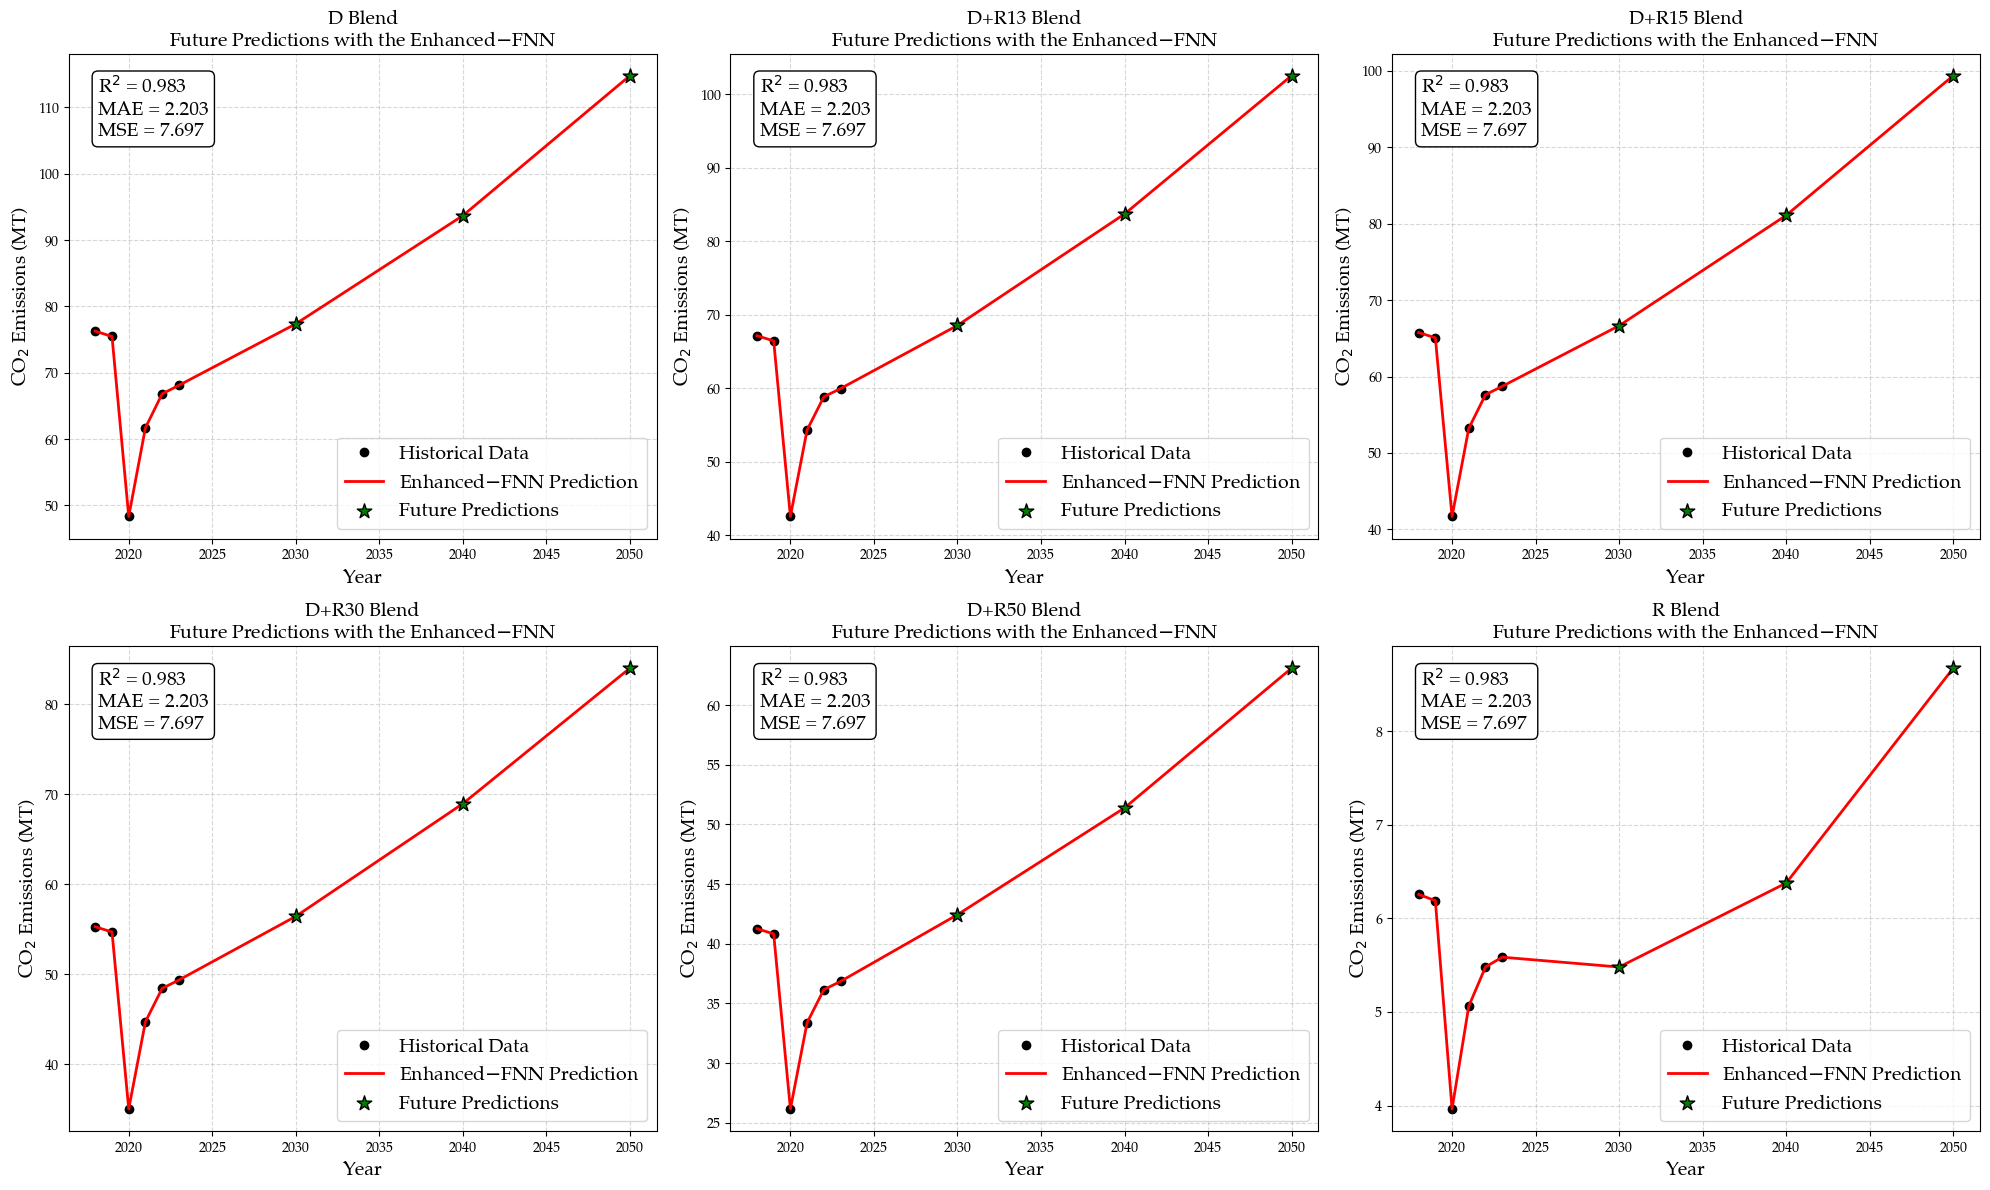

In [ ]:
### Enhanced FNN Prediction of CO₂ Emissions (2018–2050) ###
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv("/content/HVO__RAW.csv")
proj = pd.read_csv("/content/Projections___BAU___EmissionsCredits___Derived.csv")

blends = ["D", "D+R13", "D+R15", "D+R30", "D+R50", "R"]
metrics = dict(R2=0.983, MAE=2.203, MSE=7.697)

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for i, blend in enumerate(blends):
    ax = axes[i]
    hist = raw[raw["Blend"] == blend].sort_values("Year")
    pred = proj[proj["Blend"] == blend].sort_values("Year")

    years = np.concatenate([hist["Year"], pred["Year"]])
    emissions = np.concatenate([
        hist["Total Blend Emission (MT)"],
        pred["Total Blend Emission (MT)_mean"]
    ])

    ax.plot(hist["Year"], hist["Total Blend Emission (MT)"], 'ko', label="Historical Data")
    ax.plot(years, emissions, 'r-', lw=2, label="Enhanced$-$FNN Prediction")
    future_years = [2030, 2040, 2050]
    future_data = pred[pred["Year"].isin(future_years)].sort_values("Year")

    ax.scatter(
        future_data["Year"],
        future_data["Total Blend Emission (MT)_mean"],   # future predictions column
        color="green",
        s=120,
        marker="*",
        label="Future Predictions",
        zorder=6,
        edgecolors="black"
    )
    # ax.plot(pred["Year"], pred["Total Blend Emission (MT)_mean"], color='green', marker='*',
    #         zorder=6, ms=10, markeredgecolor="red", label="Future Projections")

    ax.text(0.05, 0.83,
            f"R$^{2}$ = {metrics['R2']:.3f}\nMAE = {metrics['MAE']:.3f}\nMSE = {metrics['MSE']:.3f}",
            transform=ax.transAxes, fontsize=14,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))
    ax.set_xlabel("Year", fontsize=14); ax.set_ylabel("CO$_{2}$ Emissions (MT)", fontsize=14)
    ax.set_title(f'{blend} Blend\nFuture Predictions with the Enhanced$-$FNN',
                 fontweight='bold', fontsize=14)
    ax.grid(True, ls="--", alpha=0.5)
    ax.legend(loc="lower right", fontsize=14, frameon=True)

plt.tight_layout()
plt.savefig("EnhancedFNN_CO2_Emissions.png", dpi=600)
plt.show()

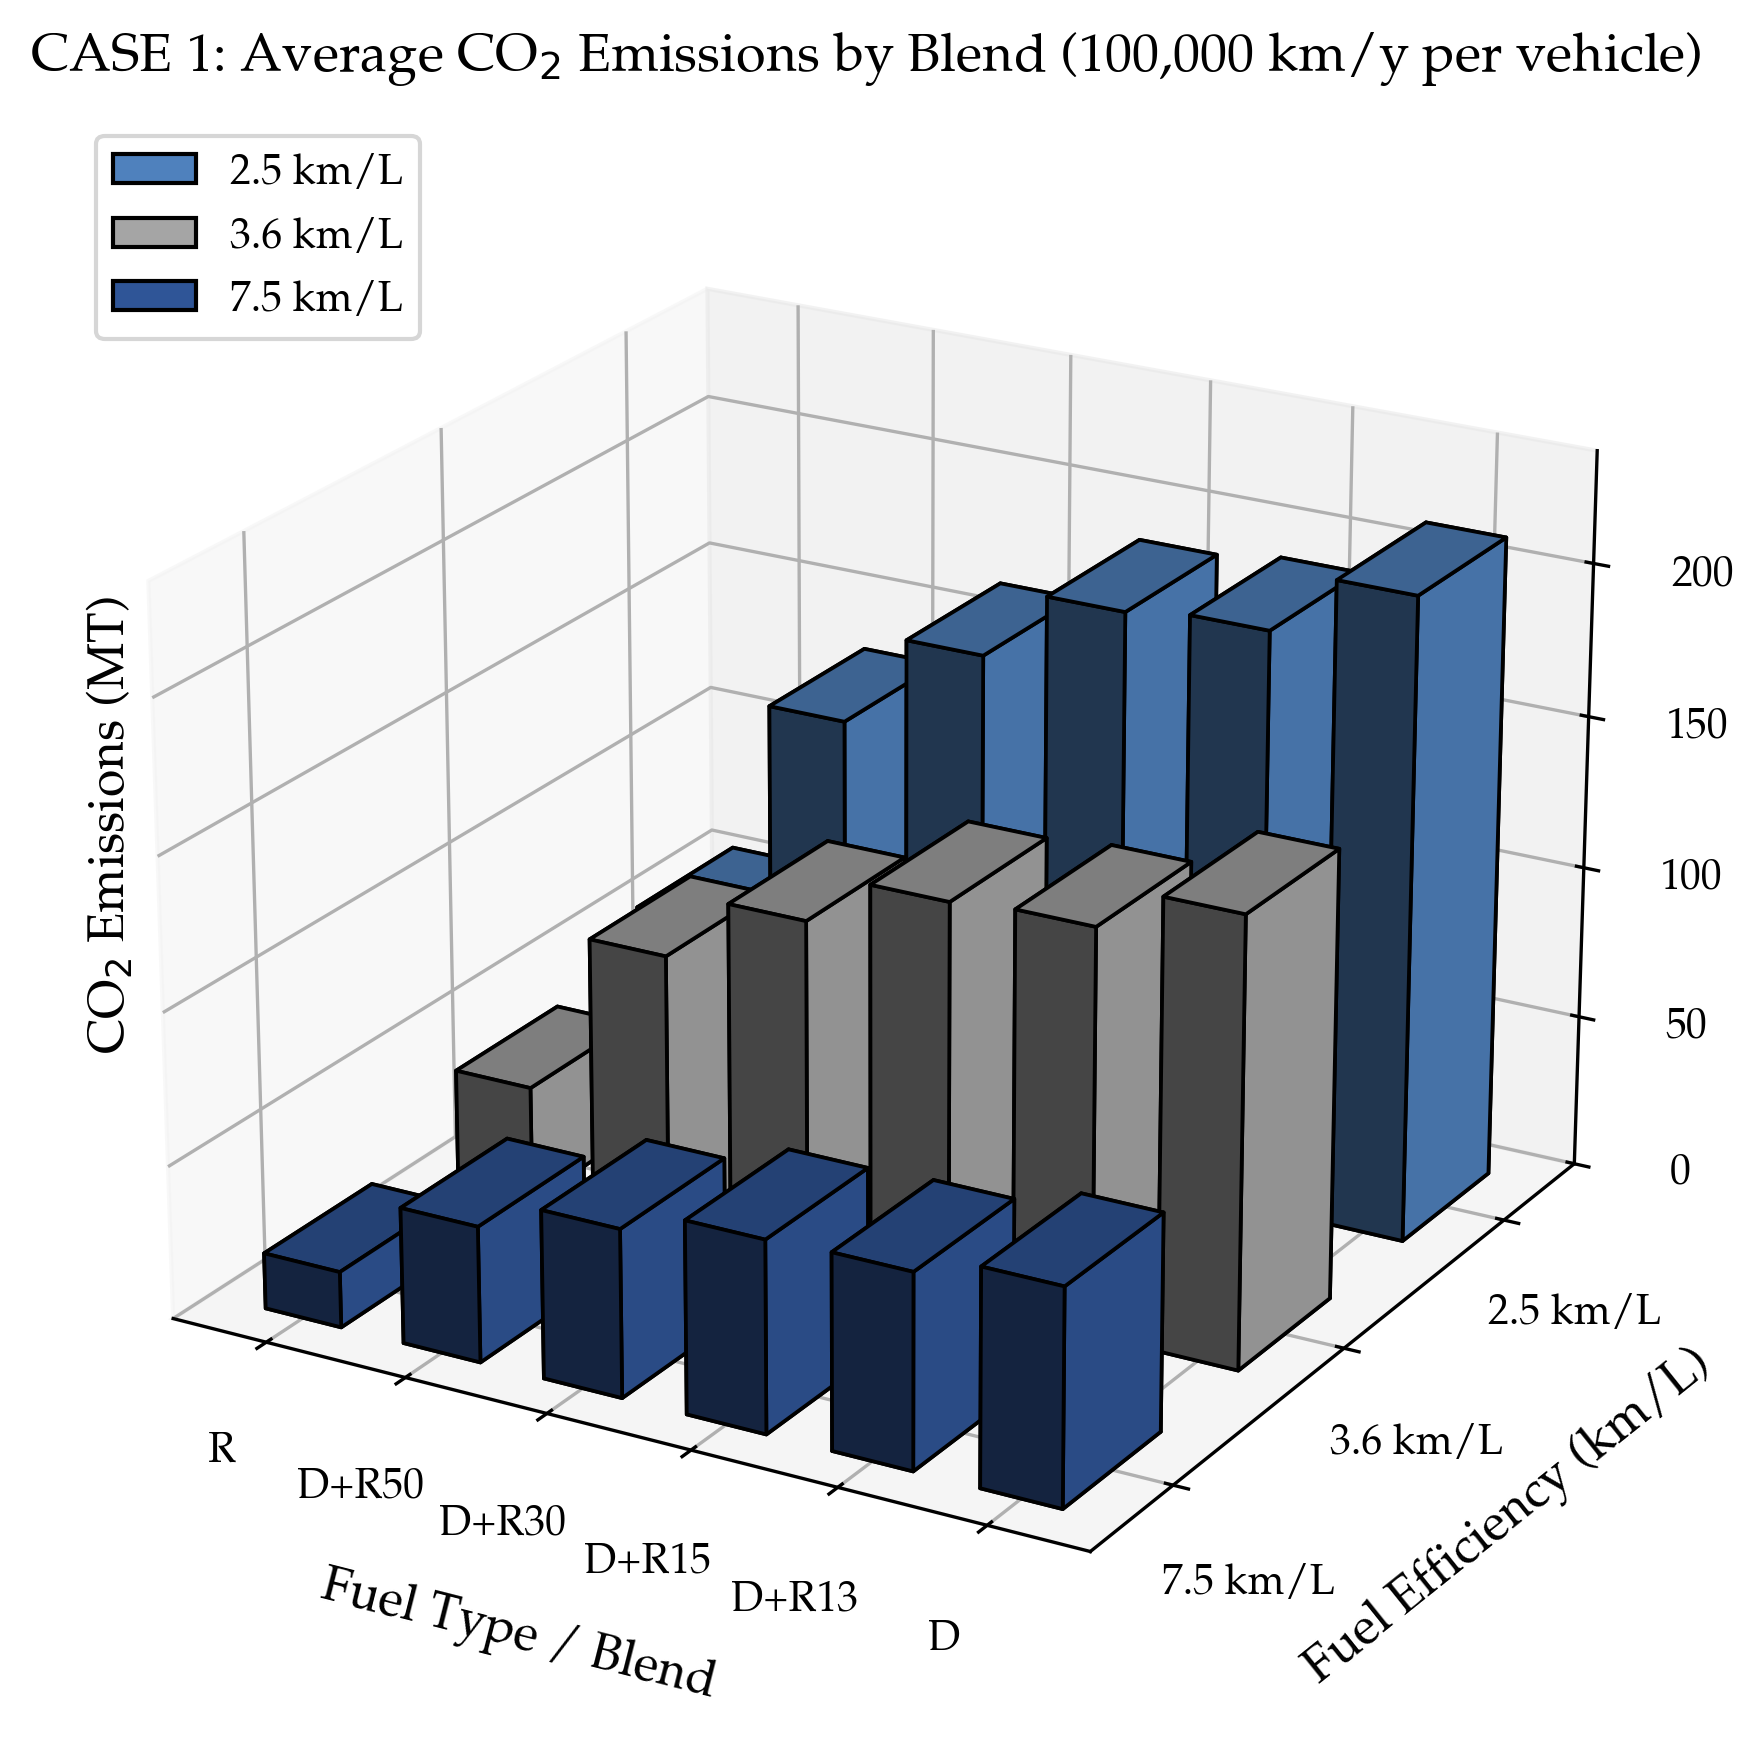

In [ ]:
### Sensitivity Analysis ###

from __future__ import annotations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D

RAW_PATH = "/content/HVO___RAW.csv"
DIESEL_PATH = "/content/DIESEL__DATA.csv"

EF_D = 2.7  # kg CO2e/L
EF_R = 0.7  # kg CO2e/L

CASE1_ANNUAL_MILEAGE = 100_000
CASE1_FE_LEVELS = [2.5, 3.6, 7.5]

CASE2_FE_FIXED = 3.6
CASE2_MILEAGES = [80_000, 100_000, 120_000]

BLENDS = ["D", "D+R13", "D+R15", "D+R30", "D+R50", "R"]


def _to_number(x) -> float:
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.integer, np.floating)):
        return float(x)
    s = str(x).strip().replace(",", "")
    return float(s) if s else np.nan


def blend_emission_factor(hvo_pct: float) -> float:
    x = float(hvo_pct) / 100.0
    return x * EF_R + (1.0 - x) * EF_D  ## kg CO2e/L


def emissions_mt(distance_km: float, f_e: float, ef_kg_per_l: float) -> float:
    ft_l = float(distance_km) / float(f_e)      ## L
    eb_tonnes = ft_l * ef_kg_per_l / 1000.0     ## tonnes
    return eb_tonnes / 1e6                      ## MT


def compute_blend_em_mt(distance_km: float, f_e: float, hvo_pct: float) -> float:
    return emissions_mt(distance_km, f_e, blend_emission_factor(hvo_pct))


def compute_credit_mt(distance_km: float, f_e: float, hvo_pct: float) -> float:
    ed = emissions_mt(distance_km, f_e, EF_D)
    eb = compute_blend_em_mt(distance_km, f_e, hvo_pct)
    return max(0.0, ed - eb)


def plot_3d_histogram(
    title: str,
    blends: list[str],
    levels: list[float],
    values_by_level: dict[float, dict[str, float]],
    *,
    zlabel: str,
    legend_labels: list[str],
    y_axis_label: str,
    out_path: str,
) -> None:
    """
    3D grouped bars with:
      - distinct colors per scenario level (legend matches)
      - black bar edges
      - clear X/Y/Z axis labels with proper spacing
      - Z ticks shown on the SAME side as the visible Z label (via azimuth)
      - legend placed inside, top-left, avoiding label clustering
      - no clipping / no shifting on save
    """
    base_colors = ["#4F81BD", "#A5A5A5", "#2F5597", "#9BBB59", "#C0504D", "#8064A2"]
    colors = [base_colors[i % len(base_colors)] for i in range(len(levels))]

    fig = plt.figure(figsize=(6, 8), dpi=300)
    ax = fig.add_subplot(111, projection="3d")

    x_pos = np.arange(len(blends), dtype=float)
    dx, dy = 0.55, 0.55
    y_pos_levels = np.arange(len(levels), dtype=float)

    for j, lvl in enumerate(levels):
        xs = x_pos
        ys = np.full_like(x_pos, y_pos_levels[j])
        zs = np.zeros_like(x_pos)
        heights = np.array([values_by_level[lvl][b] for b in blends], dtype=float)

        ax.bar3d(
            xs, ys, zs,
            dx, dy, heights,
            shade=True,
            color=colors[j],
            edgecolor="black",
            linewidth=0.9,
            zsort="average",
        )

    ##  Axes settings  ##
    ax.set_xlabel("Fuel Type / Blend", labelpad=15, fontweight="bold", fontsize=12)
    ax.set_ylabel(y_axis_label, labelpad=15, fontweight="bold", fontsize=12)
    ax.set_zlabel(zlabel, labelpad=15, fontweight="bold", fontsize=12)
    ax.text2D(
        0.02, 0.55, zlabel,
        transform=ax.transAxes,
        rotation=90,
        va="center",
        ha="left",
        fontweight="bold",
        fontsize=12,
    )

    ax.set_xticks(x_pos + dx / 2)
    ax.set_xticklabels(blends, rotation=0, ha="center")

    ax.set_yticks(y_pos_levels + dy / 2)
    ax.set_yticklabels(legend_labels)

    ax.tick_params(axis="x", pad=8)
    ax.tick_params(axis="y", pad=8)
    ax.tick_params(axis="z", pad=8)
    ax.view_init(elev=22, azim=120)

    zmax = max(float(values_by_level[lvl][b]) for lvl in levels for b in blends)
    ax.set_zlim(0, zmax * 1.12 if zmax > 0 else 1.0)

    proxies = [Patch(facecolor=colors[i], edgecolor="black") for i in range(len(levels))]
    ax.legend(
        proxies,
        legend_labels,
        loc="upper left",
        bbox_to_anchor=(0.02, 0.98),
        frameon=True,
        fontsize=10,
        borderaxespad=0.2,
    )

    ax.set_title(title, pad=6, fontweight="bold", fontsize=12)

    ## Manual setting 3D layout ##
    fig.subplots_adjust(left=0.07, right=0.97, bottom=0.16, top=0.90)
    fig.savefig(out_path, bbox_inches="tight", pad_inches=0.25)
    plt.show()


def main() -> None:
    raw = pd.read_csv(RAW_PATH)
    diesel = pd.read_csv(DIESEL_PATH)

    if not {"Blend", "HVO (%)"}.issubset(raw.columns):
        raise ValueError("HVO___RAW.csv must contain: Blend, HVO (%)")
    if not {"Year", "Total Vehicles"}.issubset(diesel.columns):
        raise ValueError("DIESEL__DATA.csv must contain: Year, Total Vehicles")

    raw = raw.copy()
    raw["HVO (%)"] = raw["HVO (%)"].map(_to_number)

    blend_to_hvo = (
        raw[["Blend", "HVO (%)"]]
        .drop_duplicates()
        .set_index("Blend")["HVO (%)"]
        .to_dict()
    )

    missing = set(BLENDS) - set(blend_to_hvo.keys())
    if missing:
        raise ValueError(f"Missing blends in HVO___RAW.csv: {sorted(missing)}")

    diesel = diesel.copy()
    diesel["Year"] = diesel["Year"].map(_to_number).astype(int)
    diesel["Total Vehicles"] = diesel["Total Vehicles"].map(_to_number)

    years = diesel["Year"].tolist()
    vehicles_by_year = diesel.set_index("Year")["Total Vehicles"].to_dict()


    ## CASE 1: 100k km/y per vehicle, varying fuel efficiency (km/L) ##

    em_case1: dict[float, dict[str, float]] = {}
    cc_case1: dict[float, dict[str, float]] = {}

    for f_e in CASE1_FE_LEVELS:
        em_case1[f_e] = {}
        cc_case1[f_e] = {}
        for blend in BLENDS:
            hvo_pct = float(blend_to_hvo[blend])
            em_vals, cc_vals = [], []
            for y in years:
                dist = float(vehicles_by_year[y]) * CASE1_ANNUAL_MILEAGE
                em_vals.append(compute_blend_em_mt(dist, f_e, hvo_pct))
                cc_vals.append(compute_credit_mt(dist, f_e, hvo_pct))
            em_case1[f_e][blend] = float(np.mean(em_vals))
            cc_case1[f_e][blend] = float(np.mean(cc_vals))

    plot_3d_histogram(
        title="CASE 1: Average CO$_{2}$ Emissions by Blend (100,000 km/y per vehicle)",
        blends=BLENDS,
        levels=CASE1_FE_LEVELS,
        values_by_level=em_case1,
        zlabel="CO$_{2}$ Emissions (MT)",
        y_axis_label="Fuel Efficiency (km/L)",
        legend_labels=[f"{f:g} km/L" for f in CASE1_FE_LEVELS],
        out_path="/content/CASE1_CO2_3D_FIXED.png",
    )

    plot_3d_histogram(
        title="CASE 1: Avg Carbon Credits by Blend (100,000 km/y per vehicle)",
        blends=BLENDS,
        levels=CASE1_FE_LEVELS,
        values_by_level=cc_case1,
        zlabel="Carbon Credit (MT)",
        y_axis_label="Fuel Efficiency (km/L)",
        legend_labels=[f"{f:g} km/L" for f in CASE1_FE_LEVELS],
        out_path="/content/CASE1_CREDIT_3D_FIXED.png",
    )


    ## CASE 2: fixed fuel efficiency, varying annual mileage ##
    em_case2: dict[float, dict[str, float]] = {}
    cc_case2: dict[float, dict[str, float]] = {}

    for m in CASE2_MILEAGES:
        key = float(m)
        em_case2[key] = {}
        cc_case2[key] = {}
        for blend in BLENDS:
            hvo_pct = float(blend_to_hvo[blend])
            em_vals, cc_vals = [], []
            for y in years:
                dist = float(vehicles_by_year[y]) * float(m)
                em_vals.append(compute_blend_em_mt(dist, CASE2_FE_FIXED, hvo_pct))
                cc_vals.append(compute_credit_mt(dist, CASE2_FE_FIXED, hvo_pct))
            em_case2[key][blend] = float(np.mean(em_vals))
            cc_case2[key][blend] = float(np.mean(cc_vals))

    plot_3d_histogram(
        title="CASE 2: Avg CO₂ Emissions by Blend (fₑ = 3.6 km/L fixed)",
        blends=BLENDS,
        levels=[float(m) for m in CASE2_MILEAGES],
        values_by_level=em_case2,
        zlabel="CO₂ Emissions (MT)",
        y_axis_label="Annual Mileage (km/year per vehicle)",
        legend_labels=[f"{m:,} km/y" for m in CASE2_MILEAGES],
        out_path="/content/CASE2_CO2_3D_FIXED.png",
    )

    plot_3d_histogram(
        title="CASE 2: Avg Carbon Credits by Blend (fₑ = 3.6 km/L fixed)",
        blends=BLENDS,
        levels=[float(m) for m in CASE2_MILEAGES],
        values_by_level=cc_case2,
        zlabel="Carbon Credit (MT)",
        y_axis_label="Annual Mileage (km/year per vehicle)",
        legend_labels=[f"{m:,} km/y" for m in CASE2_MILEAGES],
        out_path="/content/CASE2_CREDIT_3D_FIXED.png",
    )


if __name__ == "__main__":
    main()